# Module 2: Customer Segmentation using RFM Analysis & K-Means Clustering
### Senior Data Scientist & ML Engineering Portfolio
---
### Objectives:
1. **RFM Feature Engineering**: Extract Recency (R), Frequency (F), and Monetary (M) metrics from 396k+ verified customer transactions.
2. **Mathematical Normalization**: Address extreme right-skewness using `np.log1p()` and standardize feature scales with `StandardScaler`.
3. **Hyperparameter Selection**: Apply the **Elbow Method** (WCSS Inertia) and **Silhouette Analysis** across $K \in [2, 8]$.
4. **Behavioral Personas & Business Playbook**: Segment the 4,334 customer cohort into actionable marketing segments (*Champions*, *Loyal*, *At-Risk*, *Occasional*).


In [1]:
import sys
from pathlib import Path
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 6)


## 1. Calculating Behavioral RFM Features
We utilize `src.features.rfm.RFMFeatureEngineer` to compute the raw features relative to the reference date:
- **Recency**: Days elapsed since the customer's last purchase.
- **Frequency**: Total count of unique orders placed.
- **Monetary**: Cumulative GBP (£) revenue generated by the customer.


In [2]:
from src.features.rfm import RFMFeatureEngineer

fe = RFMFeatureEngineer(data_path=Path('../data/processed/online_retail_customer_centric.csv'))
rfm_df = fe.compute_rfm()
rfm_df.head()


[RFM] Loading customer-centric transactions from ../data/processed/online_retail_customer_centric.csv...


[RFM] Observation Reference Date: 2011-12-10 12:50:00
[RFM] Computed RFM features for 4,334 customers.


,CustomerID,Recency,Frequency,Monetary,AOV,Tenure,TotalUnits
0,12346,326,1,77183.60,77183.600000,326,74215
1,12347,2,7,4310.00,615.714286,367,2458
2,12348,75,4,1437.24,359.310000,358,2332
3,12349,19,1,1457.55,1457.550000,19,630
4,12350,310,1,294.40,294.400000,310,196


## 2. Statistical Skewness & Mathematical Justification for Log Transformation
Customer spend and order volume follow extreme power-law distributions.
Notice the massive gap between the 50th percentile (Median) and the Maximum values.


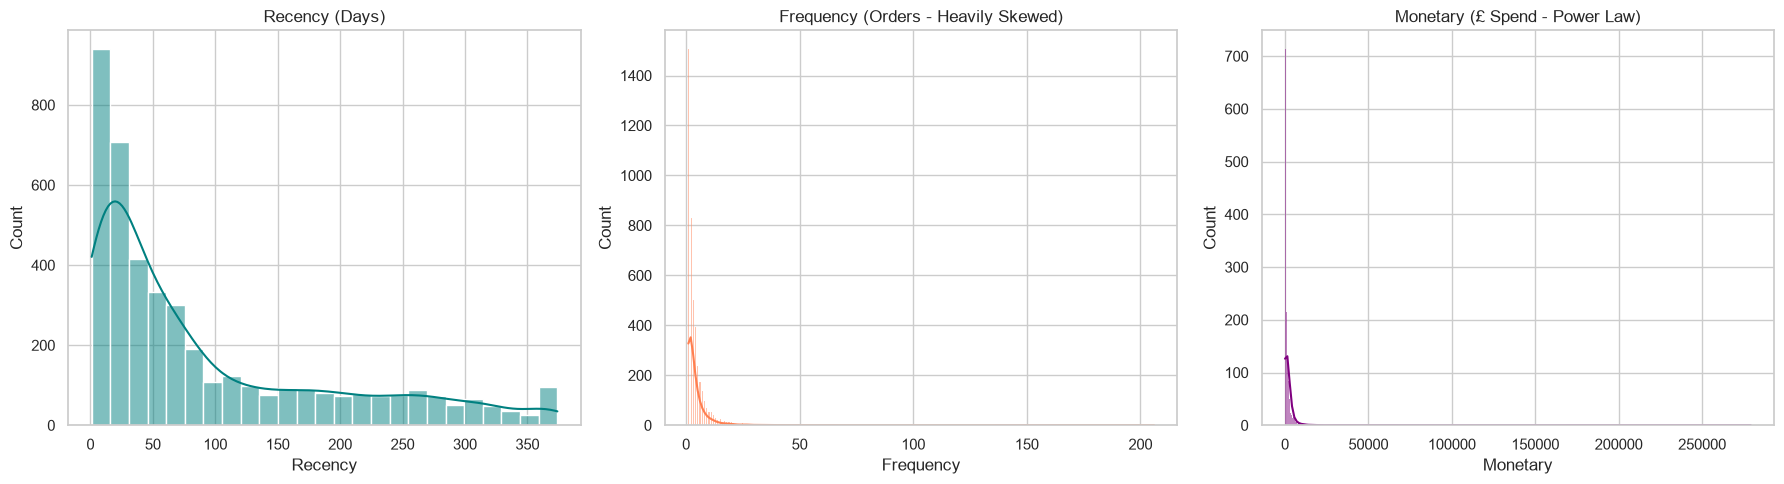

Skewness metrics:
Recency       1.24
Frequency    11.98
Monetary     19.54
dtype: float64


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(rfm_df['Recency'], kde=True, ax=axes[0], color='teal').set_title('Recency (Days)')
sns.histplot(rfm_df['Frequency'], kde=True, ax=axes[1], color='coral').set_title('Frequency (Orders - Heavily Skewed)')
sns.histplot(rfm_df['Monetary'], kde=True, ax=axes[2], color='purple').set_title('Monetary (£ Spend - Power Law)')
plt.tight_layout()
plt.show()

print("Skewness metrics:")
print(rfm_df[['Recency', 'Frequency', 'Monetary']].skew().round(2))


## 3. Selecting Optimal K (Elbow Method & Silhouette Scores)
We test $K \in [2, 8]$ using `src.models.segmentation.CustomerSegmentationModel`.
- **Inertia (Within-Cluster Sum of Squares - WCSS)**: Measures cluster compactness.
- **Silhouette Score**: Evaluates separation distance between clusters ($-1$ to $+1$).


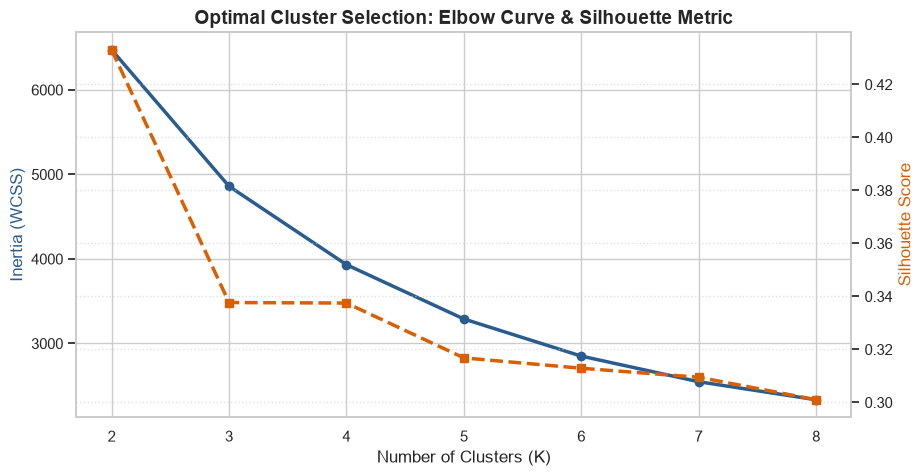

,K,Inertia_WCSS,Silhouette_Score
0,2,6474.72,0.4331
1,3,4859.79,0.3377
2,4,3932.25,0.3375
3,5,3289.89,0.3168
4,6,2850.64,0.3129
5,7,2547.66,0.3095
6,8,2334.21,0.3010


In [4]:
from src.models.segmentation import CustomerSegmentationModel

seg_model = CustomerSegmentationModel(n_clusters=4)
seg_model.prepare_features(rfm_df)
eval_df = seg_model.evaluate_cluster_range(2, 8)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()

ax1.plot(eval_df['K'], eval_df['Inertia_WCSS'], marker='o', color='#2b5c8f', linewidth=2.5, label='Inertia (WCSS)')
ax2.plot(eval_df['K'], eval_df['Silhouette_Score'], marker='s', color='#d95f02', linewidth=2.5, linestyle='--', label='Silhouette Score')

ax1.set_xlabel('Number of Clusters (K)', fontsize=12)
ax1.set_ylabel('Inertia (WCSS)', color='#2b5c8f', fontsize=12)
ax2.set_ylabel('Silhouette Score', color='#d95f02', fontsize=12)
plt.title('Optimal Cluster Selection: Elbow Curve & Silhouette Metric', fontsize=14, weight='bold')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

eval_df


## 4. Fitting Final K-Means ($K=4$) & Persona Mapping
We fit the final model and serialize the pipeline to disk.


In [5]:
segmented_df = seg_model.fit_predict()
playbook = seg_model.get_segment_playbook()
playbook[['Segment_Name', 'CustomerCount', 'AvgRecency_Days', 'AvgFrequency_Orders', 'AvgMonetary_Spend', 'Revenue_Contribution (%)']]


[Segmentation] Serialized K-Means model to: /Users/aryangupta/Desktop/e-commerce/models/kmeans_rfm_model.joblib
[Segmentation] Serialized Scaler to: /Users/aryangupta/Desktop/e-commerce/models/rfm_scaler.joblib
[Segmentation] Saved segmented customer master to: /Users/aryangupta/Desktop/e-commerce/data/processed/customer_segments.csv


,Segment_Name,CustomerCount,AvgRecency_Days,AvgFrequency_Orders,AvgMonetary_Spend,Revenue_Contribution (%)
0,At-Risk / Lapsing,1180,69.08,4.11,1784.53,24.02
1,Champions (VIP),708,11.90,13.70,7993.48,64.55
2,Loyal Customers,844,18.98,2.07,530.01,5.10
3,Occasional / Hibernating,1602,184.66,1.32,346.63,6.33


## 5. Segment Revenue Contribution (Pareto Principle in Action)
Champions constitute a minority of the customer base but drive the lion's share of revenue.


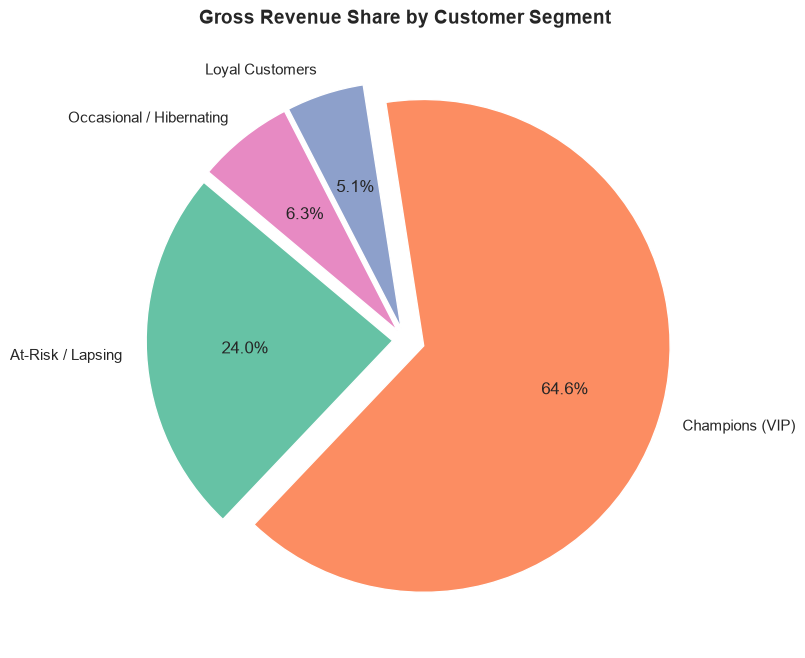

In [6]:
plt.figure(figsize=(8, 8))
plt.pie(
    playbook['Revenue_Contribution (%)'], 
    labels=playbook['Segment_Name'], 
    autopct='%1.1f%%', 
    explode=[0.05, 0.08, 0.05, 0.05],
    colors=sns.color_palette('Set2'),
    startangle=140
)
plt.title('Gross Revenue Share by Customer Segment', fontsize=14, weight='bold')
plt.show()


## 6. Interactive 3D Cluster Visualization
Inspecting how clusters separate cleanly across Recency, Frequency, and Monetary dimensions.


In [7]:
fig = px.scatter_3d(
    segmented_df, 
    x='Recency', 
    y='Frequency', 
    z='Monetary',
    color='Segment_Name',
    hover_name='CustomerID',
    log_y=True,
    log_z=True,
    opacity=0.7,
    title="3D Interactive Customer Segmentation Space (Log-Scale)"
)
fig.update_layout(margin=dict(l=0, r=0, b=0, t=40))
fig.show()


## 7. Executive Strategy & Retention Playbook
Concrete marketing actions tailored for each behavioral group:


In [8]:
for _, row in playbook.iterrows():
    print(f"==================================================")
    print(f"PERSONA: {row['Segment_Name'].upper()}")
    print(f"  • Size: {row['CustomerCount']:,} customers ({row['Revenue_Contribution (%)']}% of total revenue)")
    print(f"  • Typical Profile: Recency={row['AvgRecency_Days']:.0f} days | Orders={row['AvgFrequency_Orders']:.1f} | Avg Spend=£{row['AvgMonetary_Spend']:.2f}")
    print(f"  • ACTION PLAYBOOK: {row['Recommended_Strategy']}")


PERSONA: AT-RISK / LAPSING
  • Size: 1,180 customers (24.02% of total revenue)
  • Typical Profile: Recency=69 days | Orders=4.1 | Avg Spend=£1784.53
  • ACTION PLAYBOOK: Automated win-back email sequence, personalized 'We Miss You' discount on their favorite past items.
PERSONA: CHAMPIONS (VIP)
  • Size: 708 customers (64.55% of total revenue)
  • Typical Profile: Recency=12 days | Orders=13.7 | Avg Spend=£7993.48
  • ACTION PLAYBOOK: Exclusive rewards, early product drops, dedicated account management. Do not spam with generic discounts.
PERSONA: LOYAL CUSTOMERS
  • Size: 844 customers (5.1% of total revenue)
  • Typical Profile: Recency=19 days | Orders=2.1 | Avg Spend=£530.01
  • ACTION PLAYBOOK: Cross-sell high-affinity categories, loyalty tier accelerators, referral incentives.
PERSONA: OCCASIONAL / HIBERNATING
  • Size: 1,602 customers (6.33% of total revenue)
  • Typical Profile: Recency=185 days | Orders=1.3 | Avg Spend=£346.63
  • ACTION PLAYBOOK: Re-engagement promotions, lo